# Customer Churn Analysis

## Project Overview

The goal of this project is to analyze customer churn data, identify patterns associated with churn, and evaluate machine learning models to predict customers who may leave the service.

## Dataset

This project uses the Iranian Churn Dataset from the UCI Machine Learning Repository.

- Source: "UCI Machine Learning Repository — Iranian Churn Dataset" (https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset)
- Observations: 3,150 customers
- Features: 13 input features
- Target: "Churn" (1 = churn, 0 = no churn)
- Data context: The features describe customer activity during the first nine months, while churn is measured at the end of month 12.

The dataset contains customer usage, subscription, service, and customer-value information. It is associated with a single Iranian telecommunications company, so findings may not generalize to other providers or markets.

License: CC BY 4.0. The original dataset should be cited when reused. DOI: "10.24432/C5JW3Z" (https://doi.org/10.24432/C5JW3Z).

In [49]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [50]:
df = pd.read_csv("data/Customer_Churn.csv")

In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)
memory usa

In [52]:
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [53]:
df.isna().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

In [54]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


## Customer Churn Rate

The churn rate is 15.71%, meaning that approximately 16 out of every 100 customers in this dataset are classified as churned.

In [55]:
churn_counts = df["Churn"].value_counts()

churn_rate = df["Churn"].mean() * 100

print(f"Total customers: {len(df)}")
print(f"Churned customers: {churn_counts.get(1, 0)}")
print(f"Active customers: {churn_counts.get(0, 0)}")
print(f"Churn rate: {churn_rate:.2f}%")

Total customers: 3150
Churned customers: 495
Active customers: 2655
Churn rate: 15.71%


## Feature and Target Definition

In [56]:
X = df[["Call  Failure",
        "Complains",
        "Subscription  Length",
        "Charge  Amount",
        "Seconds of Use",
        "Frequency of use",
        "Frequency of SMS",
        "Distinct Called Numbers",
        "Age Group",
        "Tariff Plan",
        "Status",
        "Age",
        "Customer Value"]]
y = df["Churn"]

## Train-Test Split

The dataset is split into training and testing sets.
The training set is used to develop the model, while the
testing set is used to evaluate its performance on unseen data.

Stratification preserves the proportion of churned and
non-churned customers in both sets.

In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [58]:
print("X train shape:", X_train.shape)
print("X test shape:", X_test.shape)

X train shape: (2520, 13)
X test shape: (630, 13)


In [59]:
print("Churn count in train:", (y_train == 1).sum())
print("Churn count in test:", (y_test == 1).sum())

Churn count in train: 396
Churn count in test: 99


## Exploratory Data Analysis (EDA)

This section explores customer behavior and churn patterns to identify differences between churned and non-churned customers.

In [60]:
df.groupby("Churn")["Seconds of Use"].mean()

Churn
0    5014.224105
1    1566.632323
Name: Seconds of Use, dtype: float64

In [61]:
df.groupby("Churn")["Customer Value"].mean()

Churn
0    535.511501
1    124.811414
Name: Customer Value, dtype: float64

In [62]:
df_by_age = df.groupby("Age Group").agg(
    total=("Churn" , 'count'),
    churned=("Churn" , lambda x: (x==1).sum()),
)
df_by_age["churn_rate"] = df_by_age["churned"] / df_by_age["total"] * 100
print(df_by_age)

           total  churned  churn_rate
Age Group                            
1            123        0    0.000000
2           1037      184   17.743491
3           1425      230   16.140351
4            395       79   20.000000
5            170        2    1.176471


## Correlation Analysis

Correlation analysis helps identify linear relationships between numerical features and customer churn. It can also reveal features that contain overlapping information.

Text(0.5, 1.0, 'Correlation Between Selected Features and Churn')

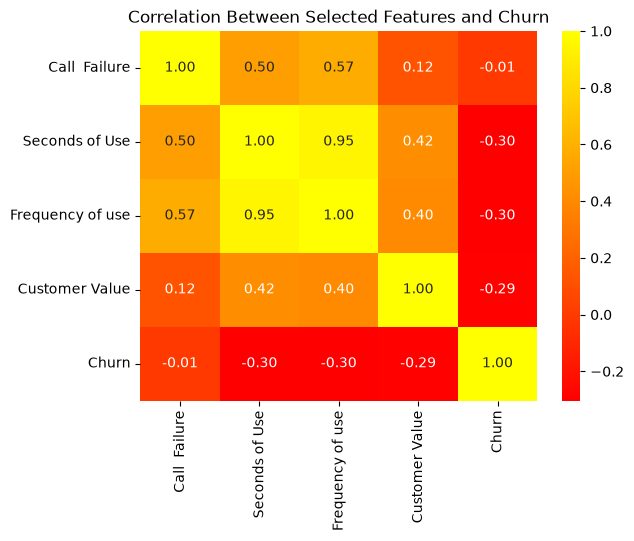

In [63]:
data = df[["Call  Failure", "Seconds of Use", "Frequency of use", "Customer Value", "Churn"]].corr()
ax = sns.heatmap(data, annot=True, fmt='.2f', cmap='autumn')
ax.set_title("Correlation Between Selected Features and Churn")

## Key Finding

- Seconds of Use: Shows a negative correlation with churn (approximately -0.30), indicating that customers with lower usage tend to have higher churn rates.
- Frequency of Use: Shows a negative correlation with churn (approximately -0.30), suggesting that customers who make fewer calls tend to be more likely to churn.
- Customer Value: Shows a negative correlation with churn (approximately -0.29), indicating that lower customer value is associated with higher churn.
- Call Failure: Shows almost no linear correlation with churn (approximately -0.01) in this dataset.
- Seconds of Use and Frequency of Use: These features are strongly positively correlated (approximately 0.95), suggesting that they contain overlapping information.

Note: Correlation does not imply causation. These findings describe associations in this dataset and do not establish why customers churn.

## Model Comparison

Six machine learning models are compared using stratified 5-fold cross-validation on the training data. Accuracy, precision, recall, and F1-score are used to evaluate model performance.

Recall is particularly important because failing to identify a customer who is likely to churn may result in a missed retention opportunity.

In [64]:
model_a = make_pipeline(StandardScaler(), LogisticRegression())
model_b = DecisionTreeClassifier(random_state=42)
model_c = RandomForestClassifier(random_state=42)
model_d = GaussianNB()
model_e = make_pipeline(StandardScaler(), KNeighborsClassifier())
model_f = make_pipeline(StandardScaler(), SVC())

models = [model_a, model_b, model_c, model_d, model_e, model_f]
model_names = ["LogisticRegression",
               "DecisionTreeClassifier",
               "RandomForestClassifier",
               "GaussianNB",
               "KNN",
               "SVM"
               ]
result = []

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy" : "accuracy",
    "precision" : "precision",
    "recall" : "recall",
    "f1" : "f1"
}

for model, name in zip(models, model_names):
    scores = cross_validate(
        model, 
        X_train,
        y_train,
        cv=cv_strategy,
        scoring=scoring
    )
    result.append({
            'model' : name, 'accuracy' : scores["test_accuracy"].mean(),
            'precision' : scores["test_precision"].mean(),
            'recall' : scores["test_recall"].mean(),
            'f1' : scores["test_f1"].mean()
            })

result_df = pd.DataFrame(result)
result_df = result_df.sort_values(
    by="f1",
    ascending=False
)
print(result_df)

                    model  accuracy  precision    recall        f1
2  RandomForestClassifier  0.955556   0.903578  0.803101  0.849999
1  DecisionTreeClassifier  0.942063   0.831710  0.795475  0.812211
4                     KNN  0.942063   0.839265  0.782880  0.809434
5                     SVM  0.918254   0.907286  0.535411  0.671539
0      LogisticRegression  0.889683   0.766747  0.434272  0.552430
3              GaussianNB  0.742857   0.373396  0.931804  0.532941


## Model Comparison Results

Random Forest achieved the best overall performance among the six evaluated models, with a mean cross-validation accuracy of 95.52%, precision of 90.57%, recall of 79.81%, and F1-score of 84.81%.

Gaussian Naive Bayes achieved the highest recall (93.18%), but its low precision (37.34%) suggests that it would incorrectly flag many non-churning customers as potential churners.

Since identifying customers at risk of churn is important, recall should be considered alongside precision and F1-score. Random Forest is selected as the leading candidate for further evaluation, subject to feature-set comparison and final model assessment.


In [65]:
X_train_no_complains = X_train.drop(columns=["Complains"])
X_train_no_status = X_train.drop(columns=["Status"])

Xs = [
    ("All features", X_train),
    ("Without Complains", X_train_no_complains),
    ("Without Status", X_train_no_status)
]

In [66]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [67]:
random_forest_result = []

for name, x in Xs:
    scores = cross_validate(
        model,
        x,
        y_train,
        cv=cv_strategy,
        scoring=scoring
    )

    random_forest_result.append({
        "feature_set": name,
        "accuracy": scores["test_accuracy"].mean(),
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f1": scores["test_f1"].mean()
    })

random_forest_result_df = pd.DataFrame(random_forest_result)
random_forest_result_df = random_forest_result_df.sort_values(
    by="f1",
    ascending=False
)

print(random_forest_result_df)

         feature_set  accuracy  precision    recall        f1
0       All features  0.955556   0.903578  0.803101  0.849999
1  Without Complains  0.945635   0.869575  0.770190  0.816409
2     Without Status  0.941270   0.874203  0.732373  0.796613


## Feature Set Comparison Results

The Random Forest model using all 13 features achieved the best performance among the three evaluated feature sets, with a mean cross-validation accuracy of 95.56% and an F1-score of 85.00%.

Removing "Complains" reduced the F1-score to 81.64%, while removing "Status" reduced it to 79.66%. Both feature removals also decreased recall, indicating that the model identified fewer customers who churned.

Based on these results, all 13 features are retained for the next stage of evaluation. This conclusion is limited to the feature sets tested in this comparison.

In [68]:
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

final_model.fit(X_train, y_train)

model_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": final_model.feature_importances_
})

model_df.sort_values(by="importance", ascending=False)

,feature,importance
1,Complains,0.187999
4,Seconds of Use,0.125854
10,Status,0.121776
2,Subscription Length,0.119341
5,Frequency of use,0.110457
7,Distinct Called Numbers,0.076977
12,Customer Value,0.076954
0,Call Failure,0.060004
6,Frequency of SMS,0.051531
8,Age Group,0.028122


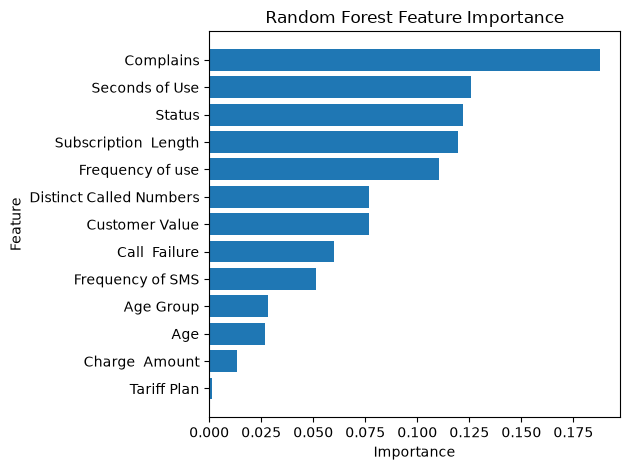

In [69]:
model_df = model_df.sort_values(by="importance", ascending=True)

plt.barh( model_df["feature"], model_df["importance"])
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [70]:
y_pred = final_model.predict(X_test)

cnf = confusion_matrix(y_true=y_test, y_pred=y_pred)
cls_report = classification_report(y_true=y_test, y_pred=y_pred)

print(cnf)
print(cls_report)

[[521  10]
 [ 14  85]]
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       531
           1       0.89      0.86      0.88        99

    accuracy                           0.96       630
   macro avg       0.93      0.92      0.93       630
weighted avg       0.96      0.96      0.96       630



## Final Model Evaluation Results

The Random Forest model achieved an accuracy of 96% on the test set. For the churn class, it achieved a precision of 89%, a recall of 86%, and an F1-score of 88%.

The model correctly identified 85 of the 99 customers who churned, while missing 14 churned customers. It also incorrectly flagged 10 customers who did not churn.

These results indicate promising predictive performance on this test split. However, because the test set was used in earlier feature-selection experiments, these metrics should not be interpreted as a fully independent estimate of the model's generalization performance.

## Business Recommendations

The churn prediction model can help a telecommunications company identify customers who may be at risk of leaving the service.

Rather than offering discounts to every flagged customer, the company should prioritize retention efforts based on churn risk, customer value, and the estimated cost of intervention.

For example, high-value customers with a high risk of churn could receive personalized offers or proactive customer support. Lower-value customers should be evaluated based on whether the expected benefit of retention justifies the intervention cost.

The company should also monitor retention campaign outcomes to determine whether these interventions actually reduce churn and generate positive financial returns.

## Limitations

- Dataset Representativeness: The dataset comes from a single telecommunications company in Iran. Therefore, the findings may not generalize to other companies, markets, or customer populations.

- Predictive vs. Causal Relationships: The model identifies patterns associated with customer churn, but these relationships do not establish the causes of churn.

- Retention Outcomes: The model predicts churn risk but does not determine whether a specific retention action, such as a discount or customer support intervention, will successfully prevent a customer from leaving.

- Evaluation Limitations: The test set was used during earlier feature-selection experiments. Therefore, the reported test performance should not be considered a fully independent final evaluation. A new holdout set or a more rigorous validation strategy would be needed for a stronger estimate of generalization performance.

- Business Impact: The model has not yet been evaluated using actual retention campaign results, intervention costs, or customer lifetime value. Therefore, its financial impact on the business remains unknown.

- Model Optimization: The Random Forest model was evaluated using its current settings. Further hyperparameter tuning and threshold optimization may improve performance or better align predictions with business priorities.

## Conclusion

This project explored customer churn patterns and compared six machine learning models using stratified 5-fold cross-validation. Random Forest achieved the best overall F1-score among the evaluated models.

A feature-set comparison showed that retaining all 13 features produced better cross-validation results than removing either "Complains" or "Status". The final Random Forest model achieved 96% accuracy and an 88% F1-score for the churn class on the test split.

The findings suggest that machine learning can help identify customers at risk of leaving a telecommunications service and support more targeted retention strategies. However, further validation and real-world retention campaign data are needed before deploying the model or measuring its financial impact.